In [ ]:
# HuffPost News Category Dataset – 210k vijesti (2012–2022) iz 42 kategorije

In [ ]:
#Uvoz biblioteka i povezivanje s Google Driveom

In [ ]:
#Instalacija gensim biblioteke koristi se za rad s vektorskim reprezentacijama riječi
# (Word2Vec, FastText) i za treniranje LDA modela tema
!pip install gensim

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.6/26.6 MB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 19.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.1
    Uninstalling scipy-1.16.1:
      Successfully uninstalled scipy-1.16.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatibl

In [ ]:
# Instalacija pyLDAvis biblioteke za vizualizaciju Lda tema
!pip install pyLDAvis

In [ ]:
# Instalcija stable-baselines3 biblioteke za pojačano učenje
!pip install stable-baselines3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.2/187.2 kB 5.7 MB/s eta 0:00:00


In [ ]:
#Instalacija "shimmy>=2.0" osigurava komatibilnost kod pojačanog učenja
!pip install "shimmy>=2.0"

In [ ]:
import pandas as pd
from google.colab import drive

#povezivanje s google drive-om i omogućavanje učitavanja skupa podataka iz google drive
drive.mount('/content/drive')



%cd /content/drive/MyDrive
%ls



Mounted at /content/drive
/content/drive/MyDrive
'Colab Notebooks'/                  Projekt1.nlogo
 dqn_news_recommender.zip           Projekt1_problemiukodu.nlogo
 Inteligentni_agenti_projekt.docx   Projekt_priprema.ipynb
 News_Category_Dataset_v3.json


In [ ]:
#Učitavanje skupa podataka

In [ ]:
#učitavanje skupa podataka koji je u formatu json
df = pd.read_json('News_Category_Dataset_v3.json', lines=True)
df.head(2)


,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23


In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209527 entries, 0 to 209526
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   link               209527 non-null  object        
 1   headline           209527 non-null  object        
 2   category           209527 non-null  object        
 3   short_description  209527 non-null  object        
 4   authors            209527 non-null  object        
 5   date               209527 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 9.6+ MB


In [ ]:
# Imamo ukupno 6 stupaca.
# 5 stupaca su tipa "object" (tekstualni podaci), a stupac 'date' je tipa datetime64[ns].

In [ ]:
df.isnull().sum()

,0
link,0
headline,0
category,0
short_description,0
authors,0
date,0


In [ ]:
#isnull potvrđuje da nema Nan vrijednosti

In [ ]:
#za svaki redak stupca headline i short_descrition se uklanjaju razmaci na početku i kraju
df['headline'] = df['headline'].str.strip()
df['short_description'] = df['short_description'].str.strip()

#ovdje se vrši dohvat redaka koji imaju prazan string
empty_headline = df[df['headline'] == ""]
empty_short_desc = df[df['short_description'] == ""]

print(f"Praznih headline: {len(empty_headline)}")
print(f"Praznih short_description: {len(empty_short_desc)}")

#ovdje se uzimaju svi redtci df koji nemaju prazan headline i short_description
df = df[(df['headline'] != "") & (df['short_description'] != "")]

Praznih headline: 6
Praznih short_description: 19712


<Axes: xlabel='category'>

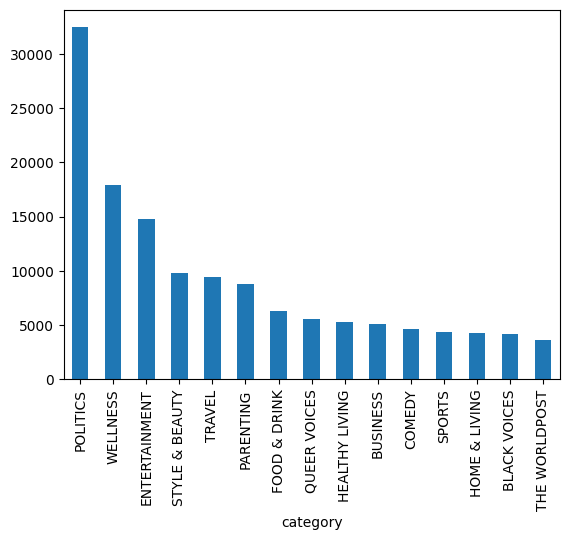

In [ ]:
df['category'].value_counts().head(15).plot.bar()


In [ ]:
# Stupčasti dijagram prikazuje 15 najzastupljenijih kategorija
#vidljivo je da kategorija POLITICS dominatna u odnosu na ostale
#vidljivo je da je prisutna velika neuravnoteženost kategorija

In [ ]:
#za svaki naslov i kratki sadržaj brojim koliko ima riječi, razdvajam svaku riječ prema razmaku
df['headline_len'] = df['headline'].apply(lambda x: len(x.split()))
df['short_desc_len'] = df['short_description'].apply(lambda x: len(x.split()))


In [ ]:
#Na ovaj način sam za svaki naslov i kratki sadržaj izračunao broj riječi, odnosno duljinu teksta u broju riječi.

In [ ]:
df['headline_len'].describe()

,headline_len
count,189814.000000
mean,9.644868
std,3.078563
min,1.000000
25%,8.000000
50%,10.000000
75%,12.000000
max,44.000000


In [ ]:
df['short_desc_len'].describe()

,short_desc_len
count,189814.000000
mean,21.711581
std,13.294908
min,1.000000
25%,13.000000
50%,20.000000
75%,26.000000
max,243.000000


In [ ]:
#dohvat proječne duljine kratkog opisa za svaku kategoriju
df.groupby('category')['short_desc_len'].mean().sort_values(ascending=False)



,short_desc_len
category,
FIFTY,45.252399
WORLDPOST,43.172303
ARTS,37.463499
EDUCATION,31.232816
WELLNESS,30.908265
PARENTING,29.704551
IMPACT,29.446857
TRAVEL,27.779747
COLLEGE,27.615635


In [ ]:
#Iz ovih prikaza sam dobio uvid u varijabilnost duljine tekstova te njihove prosječne duljine.
#Vidljivo je da su neke kategorije slične poput 'ARTS' i 'ARTS & CULTURE', ili 'COLLEGE' i 'EDUCATION'.
#Njihovo spajanje bi bilo korisno osobito kod kategorija sa manjim brojem uzoraka

In [ ]:
#uvoz Counter klase i pythonove biblioteke koja broji broj ponavljanja elemenata u listi
from collections import Counter
all_words = ' '.join(df['short_description']).lower().split()
Counter(all_words).most_common(30)


[('the', 208058),
 ('to', 117151),
 ('a', 104407),
 ('of', 99355),
 ('and', 97355),
 ('in', 67257),
 ('is', 49069),
 ('that', 43079),
 ('for', 40862),
 ('i', 31443),
 ('on', 31401),
 ('you', 31228),
 ('with', 27768),
 ('are', 26957),
 ('it', 26253),
 ('be', 22727),
 ('we', 22650),
 ('as', 21907),
 ('have', 20850),
 ('this', 20789),
 ('was', 18872),
 ('but', 18478),
 ('your', 18175),
 ('at', 17580),
 ('not', 16891),
 ('from', 16435),
 ('my', 15034),
 ('an', 14720),
 ('about', 14018),
 ('our', 13972)]

In [ ]:
all_words = ' '.join(df['headline']).lower().split()
Counter(all_words).most_common(30)


[('the', 56166),
 ('to', 48198),
 ('of', 30079),
 ('a', 29410),
 ('in', 28604),
 ('for', 23238),
 ('and', 22032),
 ('is', 15876),
 ('on', 15642),
 ('with', 12589),
 ('your', 9805),
 ('trump', 9690),
 ('you', 9626),
 ('how', 8558),
 ('(photos)', 8447),
 ('at', 8205),
 ('new', 7977),
 ('from', 7763),
 ('this', 6794),
 ('are', 6705),
 ('about', 6684),
 ('what', 5833),
 ('be', 5363),
 ('that', 5300),
 ('after', 5241),
 ('why', 5186),
 ('donald', 4760),
 ('as', 4686),
 ('it', 4360),
 ('not', 4145)]

In [ ]:
#Prikaz najčešći riječi.
#Na osnovu prikaza vidljivo je da se najviše ponavljaju stop riječi koje treba ukloniti

/tmp/ipython-input-4073945231.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_top['month'] = df_top['date'].dt.month_name()


Najpopularniji mjesec za svaku od top 15 kategorija:
          category     month  count
0         POLITICS   October   2996
1         WELLNESS     March   2027
2    ENTERTAINMENT   January   1374
3   STYLE & BEAUTY  February   1228
4           TRAVEL     March   1043
5        PARENTING     March   1017
6     FOOD & DRINK     March    736
7           SPORTS  February    566
8     QUEER VOICES      June    544
9   HEALTHY LIVING       May    528
10        BUSINESS       May    512
11          COMEDY  November    466
12   HOME & LIVING     March    435
13    BLACK VOICES     March    393
14   THE WORLDPOST     April    362


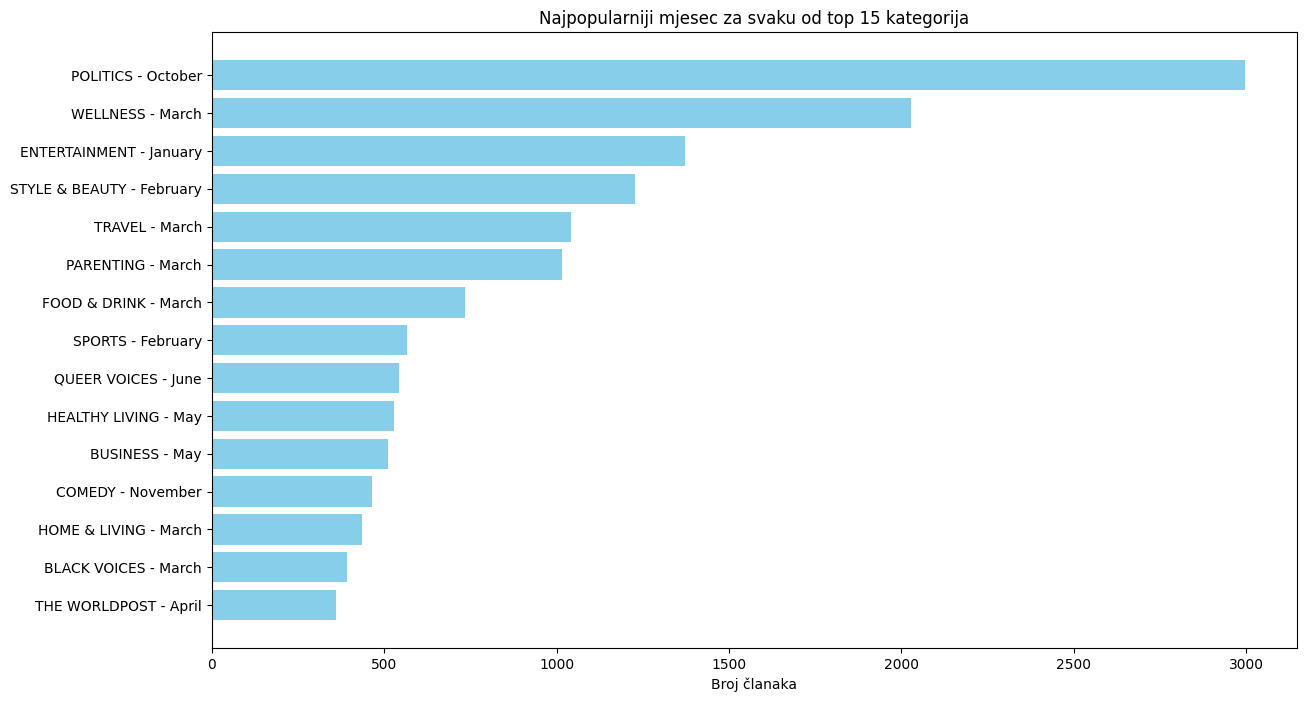

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Izračun top 15 kategorija
top_categories = df['category'].value_counts().head(15).index.tolist()

# Filtriranje podataka samo za top kategorije
df_top = df[df['category'].isin(top_categories)]

# Dodavanje stupca s mjesecom
df_top['month'] = df_top['date'].dt.month_name()

# Grupiranje po kategoriji i mjesecu
# Prebrojavanje kombinacija svake kategorije i mjeseca,
# rezultat se sprema u DataFrame sa kolonom "count".
monthly_counts = df_top.groupby(['category', 'month']).size().reset_index(name='count')

# Za svaku kategoriju pronalazimo indeks reda s najvećim brojem pojavljivanja (idxmax),
# a zatim pomoću .loc izdvajamo te redove da dobijemo najpopularniji mjesec po kategoriji
most_popular_month = monthly_counts.loc[monthly_counts.groupby('category')['count'].idxmax()]

# Sortiranje po broju članaka
most_popular_month = most_popular_month.sort_values('count', ascending=False)

# Prikaz rezultata
# Resetiranje indeksa radi urednog ispisa (stari indeksi iz monthly_counts se odbacuju).
# drop=True znači da se stari indeksi neće spremiti kao novi stupac.
print("Najpopularniji mjesec za svaku od top 15 kategorija:")
print(most_popular_month[['category', 'month', 'count']].reset_index(drop=True))

# Vizualizacija
plt.figure(figsize=(14, 8))
plt.barh(most_popular_month['category'] + ' - ' + most_popular_month['month'],
         most_popular_month['count'],
         color='skyblue')
plt.xlabel('Broj članaka')
plt.title('Najpopularniji mjesec za svaku od top 15 kategorija')
plt.gca().invert_yaxis()
plt.show()


In [ ]:
#Prikaz za 15 najpopularniji kategorija vijesti u kojem mjesecu imaju najveći broj vijesti
#naravno kategorija POLITICS ima najviše vijesti
#testirao sam kod train test split podjele da kod ulazni značajki dodam i stupac month izdvojen iz stupca date i stupac authors ali nisam dobio značajne razlike kod rezultata
#tako da sam za X samo koristio stupac text_processed koji predstavlja očišćeni tekst

In [ ]:
#Obrada i priprema podataka

In [ ]:
#zbog lakšeg praćenja za svaku vrtsu nadziranog, nenadziranog i pojačanog učenja sam definirao novi dataframe u koji sam spremio df_cleaned koji sadrzi očišćeni tekst

In [ ]:
df_cleaned = df.copy()

In [ ]:
#Spajanje naslova vijesti i kratkoga sadržaja u jedan stupac
df_cleaned['text_full'] = df_cleaned['headline'] + ' ' + df_cleaned['short_description']



In [ ]:
import re
import spacy
from spacy.lang.en.stop_words import STOP_WORDS  # standardne engleske stop riječi

# Učitavanje engleskog modela s lematizatorom
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def clean_text(text):
    # Mala slova
    text = text.lower()

    # Ukloni sve što nije slovo ili razmak
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenizacija + lematizacija + uklanjanje stop riječi
    doc = nlp(text)
    tokens = [
        token.lemma_ for token in doc
        if token.lemma_ not in STOP_WORDS
        and len(token.lemma_) > 2

    ]

    return " ".join(tokens)


In [ ]:
 #Primjena funkcije za tokenizaciju teksta i spremanje u novi stupac text_processed
df_cleaned['text_processed'] = df_cleaned['text_full'].apply(clean_text)


In [ ]:
print(df_cleaned[['text_full', 'text_processed']][:5])


                                           text_full  \
0  Over 4 Million Americans Roll Up Sleeves For O...   
1  American Airlines Flyer Charged, Banned For Li...   
2  23 Of The Funniest Tweets About Cats And Dogs ...   
3  The Funniest Tweets From Parents This Week (Se...   
4  Woman Who Called Cops On Black Bird-Watcher Lo...   

                                      text_processed  
0  million americans roll sleeve omicrontargete c...  
1  american airlines flyer charge ban life punch ...  
2  funniest tweet cat dog week sept dog understan...  
3  funniest tweet parent week sept accidentally g...  
4  woman cop black birdwatcher lose lawsuit exemp...  


In [ ]:
#Pretvaranje category iz tekstualnog oblika u numericki sa label encoderom koji podrzava i inverse transform
from sklearn.preprocessing import LabelEncoder

# Inicijalizacija
label_encoder = LabelEncoder()

# Transformacija u brojeve (original -> encoded)
df_cleaned['category_encoded'] = label_encoder.fit_transform(df_cleaned['category'])
df_cleaned['category_encoded'][:5]

,category_encoded
0,35
1,35
2,5
3,22
4,35


In [ ]:
df_cleaned.head()

,link,headline,category,short_description,authors,date,text_full,text_processed,category_encoded
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23,Over 4 Million Americans Roll Up Sleeves For O...,million americans roll sleeve omicrontargete c...,35
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23,"American Airlines Flyer Charged, Banned For Li...",american airlines flyer charge ban life punch ...,35
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23,23 Of The Funniest Tweets About Cats And Dogs ...,funniest tweet cat dog week sept dog understan...,5
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23,The Funniest Tweets From Parents This Week (Se...,funniest tweet parent week sept accidentally g...,22
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22,Woman Who Called Cops On Black Bird-Watcher Lo...,woman cop black birdwatcher lose lawsuit exemp...,35


In [ ]:
# Ovim postupkom čišćenja teksta dobiven je DataFrame s očišćenim tekstom koji će se koristiti
# u svim trima vrstama učenja: nadziranom, nenadziranom i pojačanom učenju.
# Cilj je bio maksimalno pojednostaviti tekst kako bi se uklonile riječi i znakovi koji mogu unijeti šum u model,
# poput stop riječi, brojeva i specijalnih znakova, koji često ne doprinose značajnim informacijama za model.

In [ ]:
#Nadzirano učenje

In [ ]:
df_supervised = df_cleaned.copy()

In [ ]:
#Uklanjanje duplikata kako bi se smanjio šum

In [ ]:
#  Provjera duplikata po text_full u df_supervised
duplicates_mask = df_supervised.duplicated(subset='text_full', keep=False)

print("Duplicirani redovi po text_full:")
print(df_supervised[duplicates_mask])

# Uklanjanje duplikata (ostavi prvi primjer svakog dupliciranog)
df_supervised = df_supervised.drop_duplicates(subset='text_full', keep='first').copy()

# Prikaz konačnog broja redova
print(f"\n Konačan broj redova nakon uklanjanja duplikata: {len(df_supervised)}")



Duplicirani redovi po text_full:
                                                     link  \
5225    https://www.huffpost.com/entry/netanyahu-holds...   
5226    https://www.huffpost.com/entry/israelis-vote-i...   
17640   https://www.huffingtonpost.com/entry/funniest-...   
18164   https://www.huffingtonpost.com/entry/funniest-...   
18974   https://www.huffingtonpost.com/entry/the-shape...   
...                                                   ...   
208789  https://www.huffingtonpost.com/entry/black-lov...   
208893  https://www.huffingtonpost.com/entry/watch-top...   
208929  https://www.huffingtonpost.com/entry/weekly-ro...   
209148  https://www.huffingtonpost.com/entry/were-gett...   
209521  https://www.huffingtonpost.com/entry/watch-top...   

                                                 headline        category  \
5225      Netanyahu Holds Solid Lead In Israeli Elections      WORLD NEWS   
5226      Netanyahu Holds Solid Lead In Israeli Elections      WORLD NEWS   
176

In [ ]:
df_supervised.info()

<class 'pandas.core.frame.DataFrame'>
Index: 189426 entries, 0 to 209526
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   link               189426 non-null  object        
 1   headline           189426 non-null  object        
 2   category           189426 non-null  object        
 3   short_description  189426 non-null  object        
 4   authors            189426 non-null  object        
 5   date               189426 non-null  datetime64[ns]
 6   text_full          189426 non-null  object        
 7   text_processed     189426 non-null  object        
 8   category_encoded   189426 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(7)
memory usage: 14.5+ MB


In [ ]:
#Podjela na trening i test za X sam uzeo očišćeni tekst koji je kombinacija naslova i kratkoga sadržaja.
# ciljna varijabla je category_encoded stupac koji sam prethodno sa label encoder pretvorio u brojeve

from sklearn.model_selection import train_test_split

X = df_supervised[['text_processed']]
y = df_supervised['category_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
#korištena je TF-IDF metoda koji pretvara tekst u vektore

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    #max_features ograničava na 30k najvažniji tokena
    max_features=30000,
    #uključuje riječi koje se pojavljuju u najmnaje 5 vijesti
    min_df=5,
    #ignorira riječli koje se pojavljuju u 90 posto vijesti
    max_df=0.9
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train['text_processed'])
X_test_tfidf = tfidf_vectorizer.transform(X_test['text_processed'])


In [ ]:
#također korištenje word2vec embedniga koji također tekst pretvara u vektore ali kod njega su slične riječi jednako slicnijim virjednostima vektora.
import gensim.downloader as api

# Učitaj pretrenirani model (Word2Vec Google News – 300)
w2v_model = api.load('word2vec-google-news-300')
embedding_dim = 300


[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [ ]:
#funkcija koja korisiti ucitani model word2vec kako bi prosla kroz svaku rijec i dala joj vektor

In [ ]:
#funkcija prima text, pretrenirani gensim Word2Vec model i dimenziju embeddinga
def get_mean_embedding(texts, model, dim):
    vectors = []
    for text in texts:
        words = text.split()  # 1. Razdvajamo tekst u riječi (tokenizacija jednostavnim splitom)

        # 2. Za svaku riječ iz teksta tražimo vektor iz pretreniranog Word2Vec modela
        word_vecs = [model[word] for word in words if word in model]

        if word_vecs:
            # 3. Ako imamo vektore za riječi, računamo njihov prosjek
            mean_vec = np.mean(word_vecs, axis=0)
        else:
            # 4. Ako nijedna riječ nema vektor u modelu, vraćamo vektor nula (dimenzija embeddinga)
            mean_vec = np.zeros(dim)

        # 5. Dodajemo prosječni vektor u listu rezultata
        vectors.append(mean_vec)

    # 6. Pretvaramo listu rezultata u numpy array radi lakše obrade u modelima strojnog učenja
    return np.array(vectors)



In [ ]:
#primjena funkcije i spremanje u varijable X_train_embed i X_test_embed
#za svaku vijest se dobije vektor dimenzije 300
import numpy as np
X_train_embed = get_mean_embedding(X_train['text_processed'], w2v_model, embedding_dim)
X_test_embed = get_mean_embedding(X_test['text_processed'], w2v_model, embedding_dim)


In [ ]:
print(type(X_train_tfidf))
print(type(X_train_embed))


<class 'scipy.sparse._csr.csr_matrix'>
<class 'numpy.ndarray'>


In [ ]:
from scipy.sparse import hstack



# TF-IDF matrica je sparse a dok je Word2Vec embedding dense
from scipy.sparse import csr_matrix

X_train_final = hstack([
    X_train_tfidf,
    #pretvaranje dense u sparse format
    csr_matrix(X_train_embed),

])

X_test_final = hstack([
    X_test_tfidf,
    #csr_matrix pretvara iz sparse formata u dense
    csr_matrix(X_test_embed),

])

# Provjera dimenzija
print(f"X_train_final shape: {X_train_final.shape}")
print(f"X_test_final shape: {X_test_final.shape}")


X_train_final shape: (151540, 30300)
X_test_final shape: (37886, 30300)


In [ ]:
#U nadziranom učenju odlučio sam kombinirati različite tekstualne reprezentacije u jednu zajedničku ulaznu matricu.
# Cilj je bio iskoristiti prednosti svake od njih kako bi model imao bogatiju informaciju za klasifikaciju
#Sve 2 vrste značajki spojene su horizontalno pomoću funkcije hstack, čime je dobivena jedinstvena ulazna matrica za treniranje klasičnog klasifikacijskog modela

In [ ]:
import numpy as np
#klasa za izgradnju modela
from tensorflow.keras.models import Sequential

#Dropuot za regularizaciju iskljucivanjem neurona
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

#za prilagodbu tezina treniranja
from tensorflow.keras.optimizers import Adam



# Broj klasa automatski
num_classes = len(np.unique(y_train))


# One-hot encoding labela
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_test_cat = to_categorical(y_test, num_classes=num_classes)




# Model
model = Sequential()
model.add(Dense(256, activation='relu', input_shape=(X_train_final.shape[1],)))
model.add(Dropout(0.3))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(num_classes, activation='softmax'))

# Kompajliranje
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate = 0.001 ),
    metrics=['accuracy']
)

# Treniranje
history = model.fit(
    X_train_final, y_train_cat,
    validation_data=(X_test_final, y_test_cat),
    epochs=3,
    batch_size=64,
    verbose=1
)

# Evaluacija
loss, acc = model.evaluate(X_test_final, y_test_cat, verbose=0)
print(f"Test Accuracy: {acc:.4f}")


from sklearn.metrics import classification_report


# Predikcija
y_pred_probs = model.predict(X_test_final)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test_labels, y_pred_labels))


X_train_final shape: (151540, 30300)
X_test_final shape: (37886, 30300)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 536s 223ms/step - accuracy: 0.4667 - loss: 2.0881 - val_accuracy: 0.6100 - val_loss: 1.3644
Epoch 2/3
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 63s 27ms/step - accuracy: 0.6609 - loss: 1.1766 - val_accuracy: 0.6241 - val_loss: 1.3151
Epoch 3/3
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 42s 18ms/step - accuracy: 0.7362 - loss: 0.8729 - val_accuracy: 0.6223 - val_loss: 1.3719
Test Accuracy: 0.6223
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 43s 36ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.25      0.33       173
           1       0.40      0.29      0.34       268
           2       0.54      0.40      0.46       835
           3       0.46      0.55      0.50      1026
           4       0.43      0.31      0.36       184
           5       0.51      0.50      0.50       928
           6       0.50      0.51      0.50       566
           7       0.50      0.29      0.37       212
           8       0.82    

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
#Logistička regresija maksimalan broj iteracija
model = LogisticRegression(max_iter=450)
model.fit(X_train_final, y_train)

y_pred = model.predict(X_test_final)
print(classification_report(y_test, y_pred))




              precision    recall  f1-score   support

           0       0.43      0.24      0.31       173
           1       0.39      0.23      0.29       268
           2       0.50      0.36      0.42       835
           3       0.51      0.51      0.51      1026
           4       0.42      0.34      0.38       184
           5       0.59      0.45      0.51       928
           6       0.53      0.55      0.54       566
           7       0.51      0.35      0.42       212
           8       0.80      0.72      0.76       685
           9       0.46      0.32      0.37       180
          10       0.62      0.73      0.67      2955
          11       0.42      0.26      0.32       288
          12       0.45      0.11      0.18       208
          13       0.65      0.77      0.71      1266
          14       0.44      0.20      0.27       208
          15       0.38      0.37      0.37       409
          16       0.44      0.15      0.23      1053
          17       0.73    

In [ ]:
#Logistička regresija maksimalan broj iteracija
model1 = LogisticRegression(class_weight='balanced', max_iter=1500)
model1.fit(X_train_final, y_train)

y_pred = model1.predict(X_test_final)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.22      0.50      0.31       173
           1       0.28      0.43      0.34       268
           2       0.43      0.47      0.45       835
           3       0.47      0.49      0.48      1026
           4       0.28      0.51      0.36       184
           5       0.47      0.52      0.49       928
           6       0.45      0.61      0.52       566
           7       0.31      0.44      0.36       212
           8       0.72      0.76      0.74       685
           9       0.26      0.58      0.36       180
          10       0.75      0.50      0.60      2955
          11       0.28      0.41      0.34       288
          12       0.15      0.40      0.22       208
          13       0.69      0.61      0.65      1266
          14       0.21      0.36      0.27       208
          15       0.32      0.48      0.38       409
          16       0.29      0.34      0.31      1053
          17       0.70    

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import numpy as np

# Inicijalizacija modela
xgb_model = XGBClassifier(
    objective='multi:softmax',
    num_class=len(np.unique(y_train)),
    eval_metric='mlogloss',
    max_depth=6,
    learning_rate=0.1,
    n_estimators=100,
    #automatski bira metodu gradnje stabala
    tree_method='auto',

)

# Treniranje
xgb_model.fit(X_train_final, y_train)

# Predikcija i evaluacija
y_pred_xgb = xgb_model.predict(X_test_final)
print(classification_report(y_test, y_pred_xgb))


/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [17:29:39] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "predictor", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       0.45      0.23      0.31       173
           1       0.36      0.15      0.21       268
           2       0.50      0.27      0.35       835
           3       0.48      0.44      0.46      1026
           4       0.39      0.21      0.27       184
           5       0.60      0.38      0.46       928
           6       0.49      0.50      0.49       566
           7       0.51      0.31      0.38       212
           8       0.80      0.69      0.74       685
           9       0.44      0.30      0.36       180
          10       0.49      0.68      0.57      2955
          11       0.41      0.23      0.29       288
          12       0.53      0.09      0.16       208
          13       0.62      0.77      0.69      1266
          14       0.32      0.09      0.14       208
          15       0.38      0.31      0.34       409
          16       0.45      0.10      0.16      1053
          17       0.70    

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

# Kreiranje SVM modela s balansiranjem klasa
svm_model = LinearSVC(class_weight='balanced', max_iter=500)

# Treniranje
svm_model.fit(X_train_final, y_train)

# Predikcija
y_pred_svm = svm_model.predict(X_test_final)

# Evaluacija
print(classification_report(y_test, y_pred_svm))


              precision    recall  f1-score   support

           0       0.24      0.33      0.28       173
           1       0.30      0.37      0.33       268
           2       0.45      0.46      0.46       835
           3       0.46      0.49      0.47      1026
           4       0.31      0.45      0.36       184
           5       0.52      0.51      0.51       928
           6       0.45      0.56      0.50       566
           7       0.37      0.40      0.38       212
           8       0.74      0.77      0.76       685
           9       0.31      0.44      0.36       180
          10       0.73      0.60      0.66      2955
          11       0.30      0.34      0.32       288
          12       0.20      0.26      0.23       208
          13       0.66      0.70      0.68      1266
          14       0.22      0.28      0.25       208
          15       0.31      0.42      0.36       409
          16       0.31      0.27      0.29      1053
          17       0.71    

In [ ]:
# Kreiranje SVM modela s balansiranjem klasa
svm_model1 = LinearSVC(max_iter=400)

# Treniranje
svm_model1.fit(X_train_final, y_train)

# Predikcija
y_pred_svm = svm_model1.predict(X_test_final)

# Evaluacija
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.41      0.27      0.32       173
           1       0.43      0.26      0.33       268
           2       0.50      0.42      0.46       835
           3       0.48      0.48      0.48      1026
           4       0.40      0.36      0.38       184
           5       0.57      0.47      0.52       928
           6       0.51      0.52      0.52       566
           7       0.50      0.36      0.42       212
           8       0.80      0.75      0.77       685
           9       0.47      0.36      0.40       180
          10       0.65      0.70      0.67      2955
          11       0.39      0.28      0.33       288
          12       0.33      0.14      0.20       208
          13       0.65      0.73      0.69      1266
          14       0.36      0.21      0.27       208
          15       0.38      0.36      0.37       409
          16       0.32      0.20      0.25      1053
          17       0.73    

In [ ]:
#Model bolje pogađa zanrove vijesti kod klasa koje imaju veći broj vijesti dok one koje imaju manji model ih slabije prepoznaje
#Najveću tocnost modela ima MLP neuronska mreza sa 62% također i linearni svm i loigistick regresiaj modeli imaju pribliznu tocnost
#Ne linearni modeli poput xgboost zahtijevaju vise vremena za treniranje a na kraju im je tocnost modela niza
#zbog velike e uravnotezenosti skupa podataka testirao sam i class_weight = balanced kod modela ali samim balnsiranjem koristenjem tezinski vrijednosti i sama preciznost modela pada



In [ ]:
#Ne nadzirano učenje

In [ ]:
df_unsupervised = df_cleaned.copy()


In [ ]:
import re
import spacy
import nltk
from nltk.corpus import stopwords

#Preuzimanje potrebni NLTK resursa
nltk.download('stopwords')


# NLTK stop riječi
stop_words = set(stopwords.words('english'))

# Dodavanje riječi koje nisu prisutne u NLTK stop riječima
custom_stop = {
    "youre", "im", "dont", "like", "know", "want", "think", "good",
    "new", "things", "look", "need", "theres", "little", "day", "time",
    "best", "sure", "old", "great", "check", "read", "photo", "year",
    "make", "go", "say", "see", "get", "take", "come", "use", "work",
    "try", "give", "find", "really", "never", "let", "thing", "one", "many", "however"
}
stop_words.update(custom_stop)

# Učitavanje spaCy modela
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Dozvoljeni POS tagovi
allowed_postags = ["NOUN", "ADJ", "VERB", "ADV"]

def clean_text(text):
    # Mala slova
    text = text.lower()
    # Ukloni sve osim slova i razmaka
    text = re.sub(r'[^a-z\s]', '', text)
    # Tokenizacija i lematizacija spaCy‑em
    doc = nlp(text)
    tokens = [
        token.lemma_ for token in doc
        if token.pos_ in allowed_postags and token.lemma_ not in stop_words
    ]
    return " ".join(tokens)




[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
#čišćenje teksta
df_unsupervised['short_description'] = df_unsupervised['short_description'].apply(clean_text)


In [ ]:
#LDA radi s tokeniziranim tekstom pa je iz ovoga potrebno svaku riječ kao token
texts = df_unsupervised['short_description'].apply(str.split).tolist()

In [ ]:
texts[:2]

[['health',
  'expert',
  'early',
  'predict',
  'demand',
  'match',
  'dose',
  'booster',
  'order',
  'fall'],
 ['subdue',
  'passenger',
  'crew',
  'flee',
  'aircraft',
  'confrontation',
  'office']]

In [ ]:
import gensim
from gensim.models import Phrases
from gensim.models.phrases import Phraser
from gensim import corpora, models



# BIGRAMI

#Phrases pronalazi fraze koje se pojavljuju najmanje 20 puta zajedno i na osnovu tresholda određuje se koliko su riječi povezane
bigram = Phrases(texts, min_count=20, threshold=50)

#uzima sto je phrases naucio i pretvara u verziju za koristenje
bigram_mod = Phraser(bigram)

#ovdje za svaku vijest gleda rijeci i spaja fraze koje je phrases vec naucio
texts_bi = [bigram_mod[doc] for doc in texts]

# TRIGRAMI
trigram = Phrases(texts_bi, min_count=10, threshold=50)
trigram_mod = Phraser(trigram)

#sadrži unigrame, bigrame i trigrame
texts_tri = [trigram_mod[doc] for doc in texts_bi]

# Rječnik
dictionary = corpora.Dictionary(texts_tri)

# Filtriranje ekstremnih riječi
dictionary.filter_extremes(no_below=50, no_above=0.2)

# Korpus (BoW)
corpus = [dictionary.doc2bow(text) for text in texts_tri]

print(f"Primjer tokeniziranog dokumenta s bigramima/trigramima:\n{texts_tri[0]}")
print(f"Veličina rječnika: {len(dictionary)}")


Primjer tokeniziranog dokumenta s bigramima/trigramima:
['health', 'expert', 'early', 'predict', 'demand', 'match', 'dose', 'booster', 'order', 'fall']
Veličina rječnika: 3972


In [ ]:


lda_model = models.LdaModel(
    #reprezentacija svih dokumena vrece rijeci
    corpus=corpus,
    #povezuje id-jeve za preprezentaciju tema
    id2word=dictionary,
    #je broj tema
    num_topics=10,
    #svaki pass je jedan cjelokupni prolaz kroz sve dokumente
    passes=10,
    #optimizacija za svaku vijest
    iterations=50,

    #kontrolira koliko tema prosječno ima jedan dokument
    #alpha= "auto" ,

    #kontrolira koliko riječi prosječno ima jedna tema
    #eta="auto",

    #kontrolira koliko često ažurira model
    update_every=1,

    #koliko se dokumenata obradi u jednom batchu
    #chunksize = 100,

    #vraća i distribuciju tema po svakoj pojedinačnoj riječi u dokumentu
   # per_word_topics = True,
    random_state=42
)



In [ ]:
# Funkcija za dohvat dominantne teme
#za svaku vijest pronalazi temu kojoj model pridjeljuje kao najveću vjerojatnost i zapisuje ju kao dominatnu temu.
def get_dominant_topic(lda_model, corpus):
    dominant_topics = []
    for doc_bow in corpus:
        topics = lda_model.get_document_topics(doc_bow, minimum_probability=0.0)
        # Odaberi temu s najvećom vjerojatnošću
        dominant_topic = max(topics, key=lambda x: x[1])[0]
        dominant_topics.append(dominant_topic)
    return dominant_topics

# Dodaje dominatne teme u df_unsupervised
df_unsupervised['dominant_topic'] = get_dominant_topic(lda_model, corpus)


In [ ]:
#broj vijesti
len(corpus)

189814

In [ ]:
# lista vektora za svaku vijest se izracunava vjerojatnost po temama
topic_distributions = [lda_model.get_document_topics(doc, minimum_probability=0.0) for doc in corpus]

# Pretvara listu distribucija tema po dokumentima u DataFrame
# topic_distributions je lista gdje svaki element predstavlja jedan dokument
# i sadrži listu parova (topic_id, vjerojatnost) za sve teme.
topic_df = pd.DataFrame([[prob for _, prob in doc] for doc in topic_distributions])
topic_df.columns = [f'topic_{i}' for i in range(lda_model.num_topics)]

# Spaja originalni DataFrame (df_unsupervised) s DataFrame-om tema (topic_df)
# reset_index(drop=True) -> resetira indekse df_unsupervised
# kako bi se poklapali s redovima u topic_df i izbjegli problemi pri spajanju

df_unsupervised = pd.concat([df_unsupervised.reset_index(drop=True), topic_df], axis=1)


In [ ]:
#prikaz top 7 riječi za svaku LDA temu s njihovim vjerojatnostima
for idx, topic in lda_model.print_topics(num_words=7):
    print(f"Tema {idx}: {topic}")


Tema 0: 0.030*"week" + 0.026*"last" + 0.020*"spend" + 0.020*"call" + 0.019*"report" + 0.019*"happen" + 0.018*"month"
Tema 1: 0.024*"food" + 0.020*"eat" + 0.018*"lot" + 0.017*"mother" + 0.017*"people" + 0.016*"favorite" + 0.012*"word"
Tema 2: 0.026*"mean" + 0.021*"place" + 0.019*"family" + 0.018*"travel" + 0.017*"people" + 0.015*"grow" + 0.014*"far"
Tema 3: 0.031*"people" + 0.026*"fashion" + 0.023*"wedding" + 0.020*"wear" + 0.015*"story" + 0.015*"mom" + 0.014*"person"
Tema 4: 0.020*"night" + 0.019*"bring" + 0.018*"week" + 0.018*"style" + 0.017*"dress" + 0.016*"show" + 0.015*"hard"
Tema 5: 0.046*"love" + 0.040*"feel" + 0.035*"way" + 0.032*"much" + 0.027*"well" + 0.021*"seem" + 0.019*"life"
Tema 6: 0.027*"even" + 0.026*"long" + 0.023*"experience" + 0.022*"life" + 0.021*"ever" + 0.021*"right" + 0.019*"way"
Tema 7: 0.038*"child" + 0.028*"parent" + 0.018*"couple" + 0.016*"believe" + 0.013*"city" + 0.013*"simple" + 0.013*"less"
Tema 8: 0.027*"change" + 0.018*"still" + 0.018*"important" + 0.01

In [ ]:
# Iz ovih top riječi po temama možemo pretpostaviti njihovo značenje:
# Tema 0: Tjedni izvještaji / događaji
# Tema 1: Hrana i obiteljski obroci
# Tema 2: Putovanja i obitelj
# Tema 3: Moda i vjenčanja
# Tema 4: Noćni izlazak / stil
# Tema 5: Ljubav i emocije
# Tema 6: Životna iskustva i trajanje
# Tema 7: Roditeljstvo i obitelj
# Tema 8: Promjene i društvo
# Tema 9: Komunikacija i svakodnevni razgovori


In [ ]:


import pyLDAvis.gensim_models as gensimvis
import pyLDAvis
#pyLDAvis služi za vizualizaciju LDA tema
pyLDAvis.enable_notebook()

#koristi se trenirani LDA model, isti BoW korpus i riječnik
vis = gensimvis.prepare(lda_model, corpus, dictionary)
vis


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0     -0.200928  0.095618       1        1  10.710486
5      0.248109  0.141989       2        1  10.637637
8     -0.190049 -0.078656       3        1  10.622448
3     -0.117554 -0.042587       4        1  10.074454
7     -0.065839 -0.157337       5        1   9.957894
9     -0.085860  0.058817       6        1   9.815142
1      0.109902 -0.314281       7        1   9.769806
6      0.182651  0.144938       8        1   9.630585
4     -0.076344  0.231010       9        1   9.525838
2      0.195912 -0.079511      10        1   9.255711, topic_info=        Term         Freq        Total Category  logprob  loglift
968     love  6134.000000  6134.000000  Default  30.0000  30.0000
144     feel  5327.000000  5327.000000  Default  29.0000  29.0000
357      way  6978.000000  6978.000000  Default  28.0000  28.0000
273    child  6053.000000  6053.000000  Default  27.0000  27.0000
43    people  7907.000000  7907.000000  Default  26.0000  26.0000
...      ...          ...          ...      ...      ...      ...
165      add   944.103285  1277.758118  Topic10  -4.8171   2.0773
19       put  1210.920551  2289.370901  Topic10  -4.5682   1.7430
43    people  1942.504386  7907.711413  Topic10  -4.0956   0.9761
263     life  1326.721590  7945.775471  Topic10  -4.4769   0.5900
1299  always  1030.868695  2903.367450  Topic10  -4.7292   1.3445

[423 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
1683      6  0.999282     able
697       7  0.791287   accord
697      10  0.208556   accord
527       1  0.999642      act
2765      1  0.999270  actress
...     ...       ...      ...
70        7  0.137110    world
1513      6  0.998610    worry
1845      5  0.998755    worth
1201     10  0.999122    wrong
1714      4  0.999000      yet

[487 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 6, 9, 4, 8, 10, 2, 7, 5, 3])

In [ ]:
from gensim.models import CoherenceModel
#Kreiranje objekta za evaluaciju koherentnosti LDA modela.
coherence_model = CoherenceModel(model=lda_model, texts=texts, dictionary=dictionary, coherence='c_v')

#Izračun koheretnosti modela
coherence_score = coherence_model.get_coherence()

print(f"Koherentnost (c_v) LDA modela: {coherence_score:.4f}")

Koherentnost (c_v) LDA modela: 0.3668


In [ ]:
#strozijim filtriranjem koheretnost pada ali su teme kontekstualno bolje
#koristenje bigrama i trigrama su pomogli da koheretnost i teme budu malo bolje
#najveci izazov predstavljaju omjer koliko jako filtrirati a da se ne izgubi previse znacajni rijeci a da se izbjegnu stop rijeci


In [ ]:
#Pojačano učenje - preporuke na temelju sadržaja

In [ ]:
df_rl = df_cleaned.copy()

In [ ]:
import gensim.downloader as api

# Učitavanje FastText modela (300-dimenzionalni, treniran na Wikipediji)
ft_model = api.load('fasttext-wiki-news-subwords-300')
embedding_dim = 300


[==================================================] 100.0% 958.5/958.4MB downloaded


In [ ]:
import numpy as np

def get_text_embedding(text, model, dim):
  #Dijeli tekst na riječi
    words = text.split()
    #Provjera postoji li riječ u modelu
    vectors = [model[word] for word in words if word in model]
#ako ima barem jedan vektor
    if vectors:
        return np.mean(vectors, axis=0)
        #ako nema vraća 0
    else:
        return np.zeros(dim)  # ako nema poznatih riječi


In [ ]:

text_embeddings = np.vstack(df_rl['text_processed'].apply(lambda x: get_text_embedding(x, ft_model, embedding_dim)))


In [ ]:
text_embeddings.shape


(189814, 300)

In [ ]:
import re
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Funkcija za čišćenje teksta (lower + uklanjanje interpunkcije)
def clean_text(text):
    return re.sub(r'[^\w\s]', '', text.lower())


# Uzimaju se sve jedinstvene kategorije iz DataFramea

category_names = df_rl['category'].unique().tolist()

# Generiranje embedinga za svaku kategoriju iz liste 'category_names'
#clean_text(cat) cisti text
#np.array spaja sve vijesti u  matricu dimenzije broj kategorija x dim
category_vectors = np.array([
    #funkcija prima text , ucitani model i dim
    get_text_embedding(clean_text(cat), ft_model, ft_model.vector_size)
    #prolazak for petljom za svaku vijest i racuna prosjecni embedding
    for cat in category_names
])

# Izračun matrice sličnosti između kategorija
similarity_matrix = cosine_similarity(category_vectors)


# Mapa: naziv kategorije → indeks
category_to_index = {cat: idx for idx, cat in enumerate(category_names)}


In [ ]:
print(similarity_matrix[:2])

[[1.         0.32605945 0.34825972 0.77190673 0.44072772 0.43300358
  0.47352535 0.48655757 0.48962866 0.71803026 0.41504556 0.41673924
  0.38753339 0.44770573 0.29938096 0.52786084 0.38439186 0.45437559
  0.56050353 0.47725923 0.5488485  0.47777886 0.48720304 0.43922172
  0.4602578  0.3824364  0.44484759 0.45879022 0.32690199 0.39756513
  0.5123535  0.44072772 0.30171084 0.3200545  0.40606473 0.50107307
  0.5510625  0.77174241 0.         0.3672046  0.38268394 0.33185011]
 [0.32605945 1.         0.39379784 0.44309309 0.4915664  0.34480234
  0.49307307 0.59941027 0.47120295 0.47075341 0.32689183 0.39687016
  0.43853584 0.44496279 0.33773725 0.44711483 0.48522193 0.3910044
  0.40245088 0.41918863 0.36893698 0.26676583 0.38639654 0.33583186
  0.3166902  0.37279917 0.37101036 0.29868781 0.33645307 0.37493411
  0.23008578 0.4915664  0.45616976 0.27799904 0.37046644 0.33499466
  0.3136494  0.46266353 0.         0.14507272 0.44372776 0.33541753]]


In [ ]:
# Gymnasium omogućava definiranje RL okruženja, treniranje agenata i korištenje standardnih metoda
import gymnasium as gym
from gymnasium import spaces
import numpy as np

# Definiranje okruženja koje nasljeđuje gym.Env

class NewsRecommendationEnv(gym.Env):

    #prima 3 argumenta niz vektora, listu kategorija i matricu slicnosti kategorija
    def __init__(self, embeddings, categories, similarity_matrix, category_to_index):

        #poziva se konstruktor roditeljske klase gym.Env
        #osigurava da su definirane obavezne metode reset() i step(action)
        super().__init__()

        # Pohrana ulaznih podataka u atribute klase
        self.embeddings = embeddings
        self.categories = categories
        self.similarity_matrix = similarity_matrix
        self.category_to_index = category_to_index

        #sluzi za broj vijesti u okruzenju
        self.num_items = len(embeddings)

        # Definira da su ulaz i izlaz iz okruženja realni vektor dimenzije 300
        self.observation_space = spaces.Box( low=-np.inf, high=np.inf, shape=(embeddings.shape[1],), dtype=np.float32 )

        #agent bira indeks vijesti koju želi preporučiti
        self.action_space = spaces.Discrete(self.num_items)

        #pokazivač na trenutnu vijest
        self.current_index = None

        #definira se brojač koraka u  epizodi
        self.current_step = 0

        #ovdej je postavljeno da jedna epizoda traje maksimalno 5 koraka
        self.max_steps = 5

    def reset(self, seed=None):

        # Resetiranje epizode
        super().reset(seed=seed)

        #odabire nasumicni indeks vijesti
        self.current_index = np.random.randint(0, self.num_items)

        #resetira brojač koraka na nulu na početku epizode
        self.current_step = 0

        #dohvat vektorske reprezentacije odabrane vijesti
        obs = self.embeddings[self.current_index]

        #daje informaciju o kojoj kategoriji vijesti je rijec nije od kljucne vaznosti
        info = {"category": self.categories[self.current_index]}
        return obs, info

#funkcija definira sto se događa kada agent izabere neku akciju
    def step(self, action):

        # Agent bira oju ce vijest preporuciti
        next_state = self.embeddings[action]

        #izracun nagrade ako je pogodio preporuku agenta se nagrađuje ako nije kaznjava ga se
        reward = self.get_reward(self.current_index, action)

        # Povećava broj koraka u epizodi
        self.current_step += 1

        # Epizoda završava ako je dostignut maksimalni broj koraka
        terminated = self.current_step >= self.max_steps

        # Epizoda nije nasilno prekinuta
        truncated = False

        # Ažuriranje stanja
        if terminated:
            #kada je epizoda zavrsila indeks promatrane vijest se postavlja na None
            self.current_index = None
        else:
            #u suprotnome se postavlja nova promatrana vijest
            self.current_index = action

        #info daje kategoriju vijesti
        info = {"category": self.categories[action]}

        # funkcija step vraca:
        # next_state - embedding preporučene vijesti
        # reward - nagrada na temelju relevantnosti preporuke
        # terminated - True ako je epizoda završena
        # truncated - True ako je epizoda nasilno prekinuta
        # info - dodatne informacije  (kategorija preporučene vijesti)
        return next_state, reward, terminated, truncated, info

    def get_reward(self, current_index, action_index):
        # Nagrada na temelju semantičke sličnosti kategorija
        cat_current_name = self.categories[current_index]
        cat_action_name = self.categories[action_index]

        idx1 = self.category_to_index[cat_current_name]
        idx2 = self.category_to_index[cat_action_name]
        sim = self.similarity_matrix[idx1][idx2]

        if sim >= 0.9:
            return 1.0  # točna kategorija
        elif sim > 0.7:
            return 0.5  # djelomično relevantna
        else:
            return -1.0  # nije pogodio


In [ ]:
from stable_baselines3 import DQN
from stable_baselines3.common.env_checker import check_env


# Inicijalizacija okruženja
env = NewsRecommendationEnv(
    text_embeddings,
    df_rl['category'].values,
    similarity_matrix,
     category_to_index
)

#Provjera okruženja prije treniranja
check_env(env, warn=True)


# Kreiranje DQN model-a
# koristi neuronske mreže za aproksimaciju Q-funkcije.
#koristim Multilayer Perceptron
model = DQN("MlpPolicy", env, verbose=1)

# Model uči kroz 50k koraka
#kako jedna epizoda ima 5 koraka onda bi bilo ukupno oko 10k epizoda
model.learn(total_timesteps=50000)

# Spremanje modela kako bi se kasnije koristio za evaluaciju
model.save("dqn_news_recommender")

# Ucitavanje prethodno spremljenog DQN modela
model = DQN.load("dqn_news_recommender")


Izlaz streaminga skraćen je na ovoliko posljednjih redaka: 5000.
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.622    |
|    n_updates        | 10559    |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 5        |
|    ep_rew_mean      | 2.79     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 8472     |
|    fps              | 395      |
|    time_elapsed     | 107      |
|    total_timesteps  | 42360    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.383    |
|    n_updates        | 10564    |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 5        |
|    ep_rew_mean      | 2.83     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 8

DQN preporuka točnost: 0.850


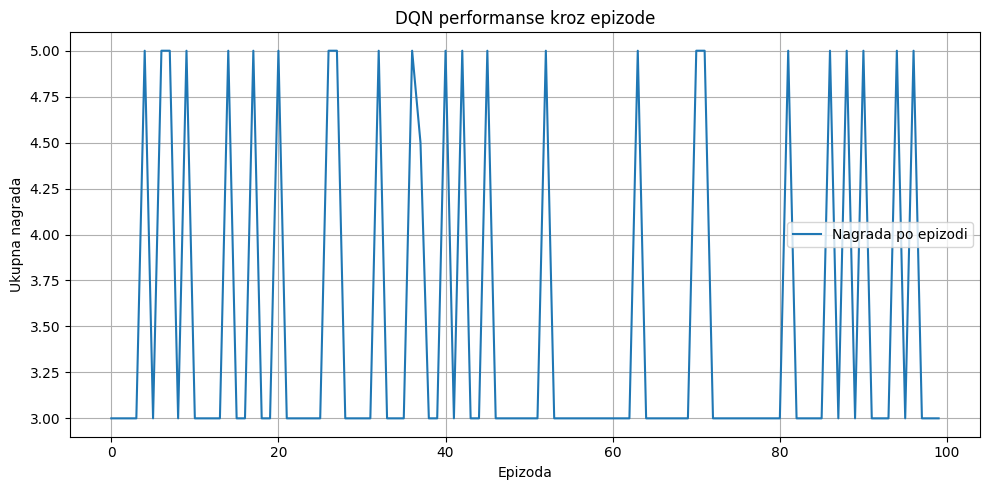

In [ ]:
import matplotlib.pyplot as plt

#broji koliko je puta agent pogodio točnu akciju
correct = 0

#broji ukupan broj koraka koje je agent napravio
total_steps = 0


#ovdje je definiran broj epizoda
n_eval_episodes = 100

#lisat u koju ce se spremati ukupne nagrade po epizodi
episode_rewards = []

for ep in range(n_eval_episodes):
    obs, info = env.reset()
    #oznacava da  je agent postigao cilj ili napravio grešku
    terminated = False

    #Oznacava da je epizoda zavrsena je je prešla vremensko ograničenje
    truncated = False

    #je akumulirani reward za jednu epizodu
    ep_reward = 0

    while not (terminated or truncated):
        # Agent bira akciju na osnovu trenutnog stanja
        action, _ = model.predict(obs, deterministic=True)

        # Izvršava akciju u okruženju i dobija nove podatke
        obs, reward, terminated, truncated, info = env.step(action)

        # Zbraja reward kroz epizodu (ukupna uspješnost)
        ep_reward += reward

        # Broji točne preporuke (reward == 1 znači da je agent pogodio)
        correct += int(reward >= 0.5)

        # Broji koliko je koraka agent napravio u epizodi
        total_steps += 1

    # Na kraju epizode se sprema ukupni reward za analizu
    episode_rewards.append(ep_reward)

# Izračun točnosti
accuracy = correct / total_steps
print(f"DQN preporuka točnost: {accuracy:.3f}")

#Crtanje grafa nagrade po epizodama
plt.figure(figsize=(10, 5))
plt.plot(episode_rewards, label="Nagrada po epizodi")
plt.xlabel("Epizoda")
plt.ylabel("Ukupna nagrada")
plt.title("DQN performanse kroz epizode")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Cilj je trenirati DQN model koji uči sekvencijalno donositi preporuke
# na temelju embeddinga zadnje vijesti koju je korisnik vidio.
# Jedna epizoda traje do 5 koraka.
# Model uči obrasce prijelaza između vijesti kako bi maksimizirao nagradu.